<a href="https://colab.research.google.com/github/quanuiter/NLI/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 – Thống kê mô tả dữ liệu (W1-07) và kiểm tra chất lượng dữ liệu (W1-08)

Hướng dẫn từng bước: `docs/huong_dan/W1-07.md`, `docs/huong_dan/W1-08.md`.
Ô có chữ **TODO** là phần m tự viết. Các ô còn lại t viết sẵn, m chạy lần lượt từ trên xuống.
Hình vẽ lưu vào `results/figures/eda_*.png` (nằm trong Drive chung) để dán vào báo cáo mục 2.

In [ ]:
# Ô 0 – cài đặt môi trường (mỗi lần mở notebook đều chạy ô này trước; Colab hỏi quyền truy cập Drive thì bấm cho phép)
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/NLI'      # lối tắt tới Drive chung (xem docs/huong_dan/README.md, mục đầu)
!git clone -q https://github.com/quanuiter/NLI.git /content/NLI 2>/dev/null || git -C /content/NLI pull -q
%cd /content/NLI
!pip install -q -r requirements.txt
import os
for sub in ['data/processed', 'tools', 'results']:
    target = os.path.join(DRIVE_DIR, sub); os.makedirs(target, exist_ok=True)
    if os.path.islink(sub): continue
    if os.path.isdir(sub):
        !cp -rn {sub}/. {target}/ && rm -rf {sub}
    os.symlink(target, sub)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/NLI


In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from src.data import DATASET_SPLITS, LABELS, load_split
from src.embeddings import tokenize

# Gộp toàn bộ dữ liệu vào bảng df (phải có 7 tập, tổng 119.776 dòng)
df = pd.concat([load_split(d, s) for d, splits in DATASET_SPLITS.items() for s in splits], ignore_index=True)
df['tap'] = df['source'] + '_' + df['split']
df.groupby('tap').size()

,0
tap,
vianli_dev,1000
vianli_test,1000
vianli_train,8012
vinli_test,2264
xnli_dev,2490
xnli_test,5010
xnli_train,100000


## 1. Phân bố nhãn

In [ ]:
pd.crosstab(df['tap'], df['label']).reindex(columns=LABELS)

label,entailment,neutral,contradiction
tap,,,
vianli_dev,334,333,333
vianli_test,334,333,333
vianli_train,2615,2924,2473
vinli_test,750,777,737
xnli_dev,830,830,830
xnli_test,1670,1670,1670
xnli_train,33333,33333,33334


**TODO 1:** đổi bảng trên sang tỉ lệ % (gợi ý: thêm `normalize='index'` vào `pd.crosstab(...)`), rồi viết 1–2 câu nhận xét:
bộ nào cân bằng nhãn, bộ nào lệch về nhãn nào.

**Nhận xét (TODO 1):** XNLI-vi (train/dev/test) và ViANLI dev/test cân bằng gần như tuyệt đối (~33,3% mỗi nhãn) do được chia đều khi xây dựng. ViANLI train hơi lệch về neutral (36,5%) và ít contradiction nhất (30,9%); ViNLI test gần cân bằng (33,1% / 34,3% / 32,6%). Vì các tập test gần như cân bằng, baseline nhãn đa số (M0) chỉ đạt accuracy khoảng 33–34%; còn macro-F1 của M0 chỉ khoảng 0,17, vì hai nhãn không bao giờ được dự đoán có F1 bằng 0. Đây là lý do nên dùng macro-F1 thay vì chỉ accuracy để so sánh mô hình.

In [ ]:
# TODO 1
bang_nhan = (pd.crosstab(df['tap'], df['label'], normalize='index') * 100).round(1).reindex(columns=LABELS)
bang_nhan

label,entailment,neutral,contradiction
tap,,,
vianli_dev,33.4,33.3,33.3
vianli_test,33.4,33.3,33.3
vianli_train,32.6,36.5,30.9
vinli_test,33.1,34.3,32.6
xnli_dev,33.3,33.3,33.3
xnli_test,33.3,33.3,33.3
xnli_train,33.3,33.3,33.3


## 2. Độ dài câu (số âm tiết)

In [ ]:
df['len_p'] = df['premise'].map(lambda s: len(tokenize(s)))
df['len_h'] = df['hypothesis'].map(lambda s: len(tokenize(s)))
df.groupby('tap')[['len_p', 'len_h']].agg(['mean', 'median', 'max']).round(1)

len_p             len_h           
              mean median  max  mean median max
tap                                            
vianli_dev    29.3   27.0   84  17.5   16.0  60
vianli_test   29.5   28.0   85  17.5   16.0  56
vianli_train  29.4   28.0  106  16.8   16.0  69
vinli_test    28.5   27.0  120  20.1   19.0  61
xnli_dev      25.4   24.0   75  12.4   12.0  35
xnli_test     25.4   24.0   71  12.4   12.0  42
xnli_train    27.2   24.0  407  13.8   13.0  73

**TODO 2:** vẽ histogram độ dài hypothesis của 3 tập `xnli_train`, `vianli_train`, `vinli_test` trên cùng một hình,
lưu `results/figures/eda_do_dai.png`. Code mẫu có trong `docs/huong_dan/W1-07.md`.
Nhận xét: bộ nào có câu dài hơn? Độ dài hypothesis có khác nhau giữa các nhãn không? (xem bằng `df.groupby(['tap','label'])['len_h'].mean()`)

**Nhận xét (TODO 2):** Hypothesis của XNLI-vi ngắn nhất (trung bình 12,4–13,8 âm tiết), ViANLI dài hơn (16,8–17,5) và ViNLI dài nhất (20,1), do ViANLI/ViNLI do người Việt viết trực tiếp còn XNLI là bản dịch từ các câu tiếng Anh ngắn. Premise của ba bộ dài tương đương (25–30 âm tiết). Ở hầu hết các tập, hypothesis của nhãn **neutral dài nhất** (XNLI train 14,7 so với 13,7 và 13,1; ViNLI 21,6 so với 19,5 và 19,0) – phù hợp với việc câu neutral thường thêm thông tin mà premise không nhắc tới (thẻ SPEC). Riêng ViANLI test, contradiction dài nhất (18,0), cho thấy dữ liệu đối kháng làm yếu đi quy luật bề mặt này.

Đã lưu /content/eda_figures/eda_do_dai.png
Đã lưu /content/NLI/results/figures/eda_do_dai.png


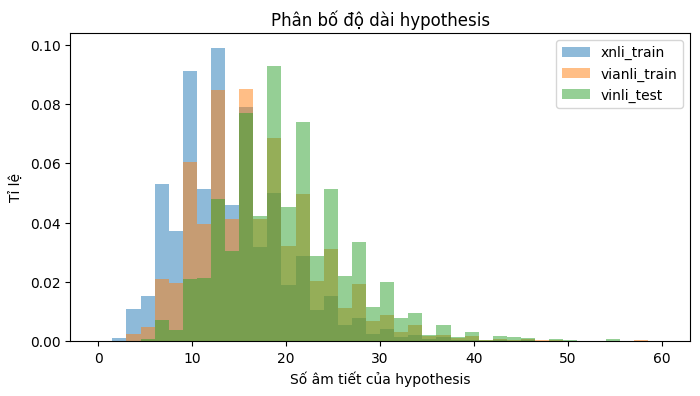

label,entailment,neutral,contradiction
tap,,,
vianli_dev,17.3,18.5,16.8
vianli_test,17.3,17.2,18.0
vianli_train,15.8,18.0,16.5
vinli_test,19.5,21.6,19.0
xnli_dev,11.7,13.5,12.2
xnli_test,11.6,13.5,12.2
xnli_train,13.7,14.7,13.1


In [ ]:
# TODO 2
import os
FIG = '/content/NLI/results/figures'   # đường dẫn tuyệt đối: thư viện tách từ có thể tự đổi thư mục làm việc
BACKUP = '/content/eda_figures'          # bản sao trên máy Colab, phòng khi Drive chung đồng bộ chậm
def luu_hinh(ten):
    for d in (BACKUP, FIG):
        try:
            os.makedirs(d, exist_ok=True)
            plt.savefig(os.path.join(d, ten), dpi=150, bbox_inches='tight')
            print('Đã lưu', os.path.join(d, ten))
        except OSError as e:
            print('Không lưu được vào', d, '-', e)

plt.figure(figsize=(8, 4))
for tap in ['xnli_train', 'vianli_train', 'vinli_test']:
    plt.hist(df.loc[df.tap == tap, 'len_h'], bins=40, range=(0, 60), alpha=0.5, label=tap, density=True)
plt.xlabel('Số âm tiết của hypothesis'); plt.ylabel('Tỉ lệ'); plt.legend()
plt.title('Phân bố độ dài hypothesis')
luu_hinh('eda_do_dai.png')
plt.show()

df.groupby(['tap', 'label'])['len_h'].mean().unstack().reindex(columns=LABELS).round(1)

## 3. Độ trùng lặp từ giữa premise và hypothesis (Jaccard, %)

In [ ]:
def jaccard(p, h):
    a, b = set(t.lower() for t in tokenize(p)), set(t.lower() for t in tokenize(h))
    return len(a & b) / max(1, len(a | b))

df['jaccard'] = [jaccard(p, h) for p, h in zip(df['premise'], df['hypothesis'])]
(df.pivot_table(index='label', columns='tap', values='jaccard') * 100).round(1).reindex(LABELS)

tap,vianli_dev,vianli_test,vianli_train,vinli_test,xnli_dev,xnli_test,xnli_train
label,,,,,,,
entailment,22.6,21.4,21.6,30.9,23.2,22.9,32.5
neutral,33.5,33.5,31.3,21.8,16.2,15.8,20.1
contradiction,33.0,30.6,31.7,24.5,16.1,16.4,21.9


**TODO 3:** vẽ biểu đồ cột cho bảng trên (gợi ý: `bang.plot.bar()` rồi `plt.savefig('results/figures/eda_jaccard.png', dpi=150, bbox_inches='tight')`).
Nhận xét: ở bộ nào các cặp entailment có độ trùng lặp từ cao nhất? ViANLI có ngược lại không? (Số liệu phải khớp `docs/ket_qua_m2.md` mục 4.)

**Nhận xét (TODO 3):** Số liệu khớp `docs/ket_qua_m2.md` mục 4. Ở XNLI-vi và ViNLI, các cặp **entailment có độ trùng lặp từ cao nhất** (XNLI train 32,5%, ViNLI 30,9%), tức hypothesis chép lại nhiều từ của premise. ViANLI thì **ngược lại**: entailment có độ trùng thấp nhất (21,4% ở test), còn neutral và contradiction cao hơn hẳn (33,5% và 30,6%), vì người viết ViANLI cố tình không chép từ của premise để đánh lừa mô hình. Do đó mô hình học trên XNLI-vi dễ học quy luật bề mặt "trùng từ nhiều → entailment" và sai hàng loạt khi đánh giá trên ViANLI.

Đã lưu /content/eda_figures/eda_jaccard.png
Đã lưu /content/NLI/results/figures/eda_jaccard.png


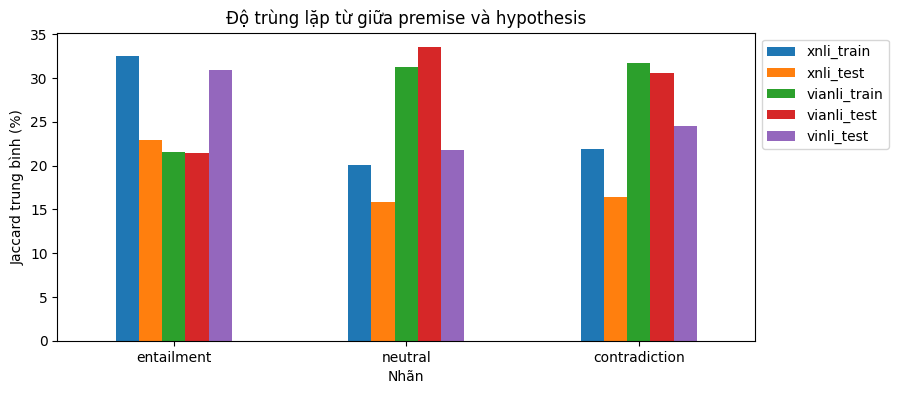

tap,xnli_train,xnli_test,vianli_train,vianli_test,vinli_test
label,,,,,
entailment,32.5,22.9,21.6,21.4,30.9
neutral,20.1,15.8,31.3,33.5,21.8
contradiction,21.9,16.4,31.7,30.6,24.5


In [ ]:
# TODO 3
bang = (df.pivot_table(index='label', columns='tap', values='jaccard') * 100).round(1).reindex(LABELS)
bang = bang[['xnli_train', 'xnli_test', 'vianli_train', 'vianli_test', 'vinli_test']]
ax = bang.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel('Jaccard trung bình (%)'); ax.set_xlabel('Nhãn')
ax.set_title('Độ trùng lặp từ giữa premise và hypothesis')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
luu_hinh('eda_jaccard.png')
plt.show()
bang

## 4. Tần suất từ phủ định theo nhãn

**Nhận xét (TODO 4):** Ở XNLI-vi, từ phủ định trong hypothesis là **dấu hiệu rất mạnh của contradiction**: 42,0% câu contradiction ở train (45,5% ở test) có từ phủ định, gấp khoảng 2,5 lần entailment (17,0%) và neutral (18,7%) – đây là hiện tượng lộ nhãn qua hypothesis mà M1-h sẽ kiểm tra. ViNLI cũng có xu hướng này nhưng yếu hơn (30,7% so với 16,1% và 14,9%); con số 30,7% cao hơn mức 22% câu contradiction "được tạo bằng từ phủ định" trong bài ViNLI vì ở đây ta đếm mọi câu có từ phủ định, kể cả khi phủ định không quyết định nhãn. Ở ViANLI tín hiệu này gần như biến mất (train 13,8 / 12,0 / 16,9%; test 17,7 / 13,5 / 17,1%, entailment ngang contradiction), nên mô hình dựa vào từ phủ định sẽ không hiệu quả trên dữ liệu đối kháng.

Đã lưu /content/eda_figures/eda_phu_dinh.png
Đã lưu /content/NLI/results/figures/eda_phu_dinh.png


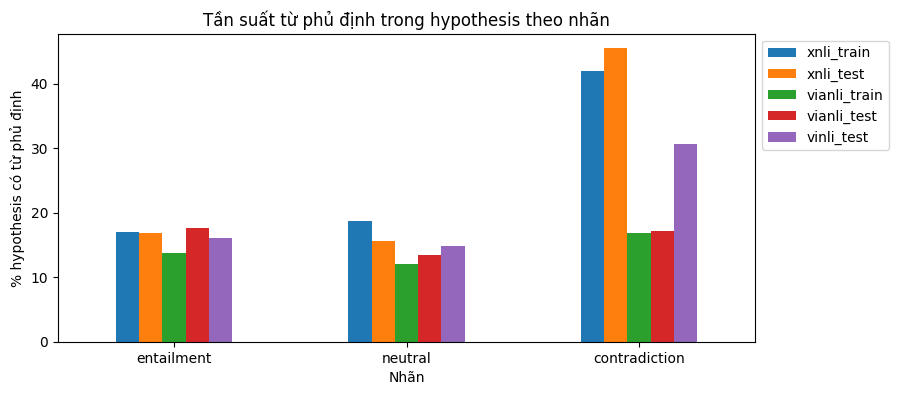

tap
xnli_train      42.0
xnli_test       45.5
vianli_train    16.9
vianli_test     17.1
vinli_test      30.7
Name: contradiction, dtype: float64


tap,xnli_train,xnli_test,vianli_train,vianli_test,vinli_test
label,,,,,
entailment,17.0,16.9,13.8,17.7,16.1
neutral,18.7,15.7,12.0,13.5,14.9
contradiction,42.0,45.5,16.9,17.1,30.7


In [ ]:
NEG = r'\b(?:không|chưa|chẳng|chả|đâu có|không hề|chưa từng)\b'
# TODO 4: tỉ lệ (%) hypothesis có từ phủ định, theo nhãn và theo tập
df['h_neg'] = df['hypothesis'].str.contains(NEG, case=False, regex=True)
bang_neg = (df.pivot_table(index='label', columns='tap', values='h_neg') * 100).round(1).reindex(LABELS)
bang_neg = bang_neg[['xnli_train', 'xnli_test', 'vianli_train', 'vianli_test', 'vinli_test']]
ax = bang_neg.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel('% hypothesis có từ phủ định'); ax.set_xlabel('Nhãn')
ax.set_title('Tần suất từ phủ định trong hypothesis theo nhãn')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
luu_hinh('eda_phu_dinh.png')
plt.show()
# Tỉ lệ trong các câu contradiction (so với con số 22% của bài ViNLI)
print(bang_neg.loc['contradiction'])
bang_neg

---
# Phần W1-08: kiểm tra chất lượng dữ liệu

In [ ]:
# 5. Câu rỗng hoặc quá ngắn (câu như "Đúng vậy." vẫn hợp lệ, không tính là lỗi)
df[(df['len_p'] < 3) | (df['len_h'] < 2)][['tap', 'premise', 'hypothesis', 'label']].head(20)

# Đếm số lượng theo tập
ngan = df[(df['len_p'] < 3) | (df['len_h'] < 2)]
print('Số mẫu rất ngắn theo tập:'); print(ngan.groupby('tap').size())
print('Câu rỗng hoàn toàn:', int(((df['premise'].str.strip() == '') | (df['hypothesis'].str.strip() == '')).sum()))
print('Ký tự lỗi encoding (\ufffd):', int(df['premise'].str.contains('\ufffd').sum() + df['hypothesis'].str.contains('\ufffd').sum()))

Số mẫu rất ngắn theo tập:
tap
xnli_train    286
dtype: int64
Câu rỗng hoàn toàn: 0
Ký tự lỗi encoding (�): 1


In [ ]:
# 6. Mẫu trùng lặp trong cùng một tập
dup = df[df.duplicated(['tap', 'premise', 'hypothesis'], keep=False)]
print(dup.groupby('tap').size())
# TODO 6: trong các mẫu trùng lặp, có cặp nào giống hệt nhau nhưng KHÁC nhãn không? (code mẫu trong docs/huong_dan/W1-08.md)
g = df.groupby(['tap', 'premise', 'hypothesis'])['label'].nunique()
khac_nhan = g[g > 1]
print('Cặp trùng nhưng khác nhãn theo tập:'); print(khac_nhan.groupby(level='tap').size())
khac_nhan.head(10)

tap
vianli_test     2
xnli_train     39
dtype: int64
Cặp trùng nhưng khác nhãn theo tập:
tap
xnli_train    15
Name: label, dtype: int64


tap         premise                                                                                                                                                                                                                           hypothesis                                                                                            
xnli_train  Chương trình somerset county của công ty tự do dân sự mỹ giữ một phòng khám pháp lý miễn phí vào thứ năm thứ của mỗi tháng.                                                                                                       Một phòng khám pháp lý miễn phí được tổ chức vào thứ năm thứ của mỗi tháng.                               2
            Các nhà khoa học chỉ ra rằng mô hình động vật transplanting vào phôi con người còn gần hơn là nhân bản của con người.                                                                                                             Transplanting động vật mô vào phôi con người còn gần hơn là nhân bản của con người.                       2
            Những ngày hoạt động bị hạn chế nhỏ $ 48 cho mỗi case3 trung bình wtp ước tính để tránh một mrad từ juli, et al.                                                                                                                  Những ngày hoạt động bị hạn chế nhỏ $ 48 cho mỗi trường hợp                                               2
            Phục vụ các bữa ăn jamaica với ảnh hưởng châu âu trong một nhà hàng được thiết kế mới được thiết kế trên đỉnh vách đá, cung cấp một vị trí lý tưởng cho cocktail hoàng hôn.                                                       Họ phục vụ đồ ăn jamaica ở bên ngoài.                                                                     2
            Sử dụng của 3.6 MG / L (Anhydrous) natri thiosunfat sẽ giảm 1.0 mg chlorine / L (apha, 1992).                                                                                                                                     Sử dụng của 3.6 MG / L (Anhydrous) natri thiosunfat sẽ giảm mức độ của 1.0 mg chlorine / L                2
            Thay vào đó, theo phần 23 (a) (2) của hành động trao đổi chứng khoán của 1934, 15                                                                                                                                                 Hướng dẫn lắp vỏ chìa kia (2)                                                                             2
            Thật sự thất vọng, thật đấy.                                                                                                                                                                                                      Thật sự là thất vọng.                                                                                     2
            Tuy nhiên, một yếu tố quan trọng nhất của một tổ chức thành công là sự cam kết duy trì của các nhà lãnh đạo hàng đầu cho các chiến lược hiện đại, hiệu quả và đáng tin cậy của con người và để thiết lập các mục tiêu rõ ràng và  Sự cam kết duy trì của các nhà lãnh đạo hàng đầu là yếu tố quan trọng nhất của một tổ chức thành công.    2
            Tôi? kembecis sẽ mở cửa cho đến khi sáng sớm để phục vụ bát súp Bee để đói bụng đêm khuya trên đường về nhà.                                                                                                                      Na na na na na na na na na na na                                                                          2
            Uh uh uh uh uh uh uh uh uh uh uh uh uh uh uh uh uh uh uh                                                                                                                                                                          Phải, đúng vậy.                                                                                           2
Name: label, dtype: int64

In [ ]:
# 7. Rò rỉ dữ liệu: cặp câu của tập test có xuất hiện trong tập train không?
def leak(train_tap, test_tap):
    tr = set(zip(df.loc[df.tap == train_tap, 'premise'], df.loc[df.tap == train_tap, 'hypothesis']))
    te = df[df.tap == test_tap]
    n = sum((p, h) in tr for p, h in zip(te['premise'], te['hypothesis']))
    return n, len(te)

for a, b in [('xnli_train', 'xnli_test'), ('vianli_train', 'vianli_test'), ('vianli_train', 'vinli_test')]:
    print(a, '->', b, leak(a, b))
# TODO 7: làm tương tự nhưng chỉ so sánh premise, ghi lại số lượng
def leak_premise(train_tap, test_tap):
    tr = set(df.loc[df.tap == train_tap, 'premise'])
    te = df[df.tap == test_tap]
    n_mau = int(te['premise'].isin(tr).sum())
    n_p = int(te['premise'].drop_duplicates().isin(tr).sum())
    return n_mau, n_p, te['premise'].nunique()

print('(số mẫu test có premise trùng, số premise khác nhau bị trùng, tổng premise khác nhau của tập test)')
for a, b in [('xnli_train', 'xnli_test'), ('vianli_train', 'vianli_test'), ('vianli_train', 'vinli_test')]:
    print(a, '->', b, leak_premise(a, b))

xnli_train -> xnli_test (0, 5010)
vianli_train -> vianli_test (2, 1000)
vianli_train -> vinli_test (0, 2264)
(số mẫu test có premise trùng, số premise khác nhau bị trùng, tổng premise khác nhau của tập test)
xnli_train -> xnli_test (0, 0, 1669)
vianli_train -> vianli_test (956, 865, 893)
vianli_train -> vinli_test (29, 5, 377)


**TODO 8 – bảng tổng kết:** *loại lỗi · số lượng · cách xử lý*. Các lỗi t đã xử lý có sẵn trong `docs/huong_dan/W1-08.md`,
m chép sang rồi bổ sung kết quả ô 5–7. Bảng này đưa vào báo cáo mục 2.

| Loại lỗi | Số lượng | Cách xử lý |
|---|---|---|
| Dấu cách trước dấu câu (XNLI train) | ~91% câu | Đã chuẩn hóa trong `src/data.py` |
| Chưa chuẩn hóa Unicode NFC (ViANLI) | ~1,7% câu | Đã chuẩn hóa NFC |
| `uid` của ViANLI chứa mã nhãn | 100% dev/test | Không dùng `id` làm đặc trưng; bỏ `id` khỏi file gán nhãn độc lập |
| Hai kiểu đặt dấu thanh (hóa / hoá) | – | Chuyển đổi khi tra word embedding (`src/embeddings.py`) |
| Câu rỗng hoàn toàn | 0 | Không cần xử lý |
| Câu rất ngắn (premise < 3 hoặc hypothesis < 2 âm tiết) | 286 mẫu, đều ở XNLI train (280 premise, 17 hypothesis) | Giữ nguyên: phần lớn là câu hội thoại hợp lệ ("Rất tốt.", "Chi phí!"); một số do lỗi dịch/ký tự lạ nhưng chỉ chiếm 0,3% tập train |
| Ký tự lỗi encoding (`\ufffd`) | 1 mẫu (XNLI train) | Giữ nguyên: chỉ 1 ký tự trong tên riêng, không ảnh hưởng nhãn |
| Mẫu trùng lặp (cùng premise + hypothesis) trong một tập | XNLI train: 39 dòng (19 cặp); ViANLI test: 2 dòng (1 cặp) | Giữ nguyên: số lượng rất nhỏ (< 0,04%), không làm lệch kết quả |
| Cặp trùng nhưng khác nhãn | 15 cặp (XNLI train) | Giữ nguyên trong train (nhiễu nhãn của bản dịch máy); ghi nhận là hạn chế của dữ liệu |
| Rò rỉ cặp câu train → test | XNLI: 0/5.010; ViANLI: 2/1.000; ViNLI (so với ViANLI train): 0/2.264 | Giữ nguyên: 2 mẫu ViANLI (0,2%) không ảnh hưởng đáng kể; báo cáo minh bạch |
| Premise của test xuất hiện trong train | XNLI: 0; ViANLI: 956/1.000 mẫu (865/893 premise); ViNLI: 29/2.264 mẫu (5 premise) | Giữ nguyên: ViANLI dùng chung đoạn văn cho nhiều vòng đối kháng (theo thiết kế ANLI), hypothesis mới khác hoàn toàn nên không phải rò rỉ nhãn; cần lưu ý khi diễn giải kết quả ViANLI |